# Meilenstein 3 — Dateninput minimieren

Fortsetzung des SVM-Notebooks aus Meilenstein 2 (vorher `milestone2_model_new.ipynb`; die M2-Version liegt in der Git-History, die Ergebnisse in `MILESTONE2_REPORT.md`). Die Daten kommen wie in M2 aus `data/processed/cleaned_data.csv` (erzeugt mit `python pipeline/_run_pipeline.py`).

**Fragestellung (Aufgabenstellung 4.1.2 / Meilenstein 3):** Lässt sich der Dateninput reduzieren, ohne die Klassifikationsleistung wesentlich zu verschlechtern — und wie sieht der Trade-off „Qualität vs. Input" aus? Die Beispiele der Aufgabenstellung (1–2-jährige Sequenzen, Sommerfenster, wenige Zeitstempel) stammen aus einem Zeitreihen-Setting. Bei uns ist jede Zeile **eine einzelne Aufnahme**, die Sequenzachse ist die Wellenlänge. Wir übertragen die Frage deshalb auf drei Input-Achsen:

1. **Spektral** (Hauptachse): Wie viele und welche Bänder müssen gemessen werden? Feature-Gruppen, Vegetationsindizes, Bandauswahl (gleichmäßig verteilt, `SelectKBest`, PCA) und die Simulation eines Multispektralsensors (Sentinel-2).
2. **Zeitlich:** Wie gut klappt die Klassifikation je Aufnahmemonat — reicht ein Sommerfenster? Wie wichtig ist das `Month`-Feature?
3. **Trainingsdaten:** Wie viele gelabelte Samples braucht das Modell (Lernkurve)?

Zum Abschluss: Trade-off-Kurve, Wahl eines reduzierten Modells mit einmaliger Testsplit-Auswertung und als **Bonus** eine Feature-Importance-Analyse (gruppierte Permutation Importance der SVM, SHAP pro Klasse und Wellenlänge).

**Wichtige Unterscheidung — weniger Features ≠ weniger Messung:** PCA oder Spektral-Statistiken (Mittelwert, Gradienten …) verdichten das Spektrum, brauchen aber weiterhin **alle** Bänder als Messung. Für eine praktische Datenreduktion (günstigerer Sensor, weniger Speicher und Übertragung) zählt die Spalte `n_baender` = Anzahl der Bänder, die tatsächlich gemessen werden müssen. `Month` und `AEZ` sind Metadaten und praktisch kostenlos.

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score, cross_val_predict,
                                     learning_curve, RandomizedSearchCV)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, make_scorer, ConfusionMatrixDisplay
import shap

# dieselben Index-Formeln wie die Pipeline, für die Sentinel-2-Simulation
from pipeline.src.data_prep import _engineer_spectral_features

# kleine Trainingsteilmengen (Lernkurve) sagen nicht jede Klasse in jedem Fold vorher
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')
# feste Farbreihenfolge (farbfehlsichtigkeitsgeprüfte Palette), damit Klassen/Methoden immer gleich gefärbt sind
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                                                    '#e87ba4', '#008300', '#6250d6', '#e34948'])

RANDOM_STATE = 42
df = pd.read_csv('data/processed/cleaned_data.csv')

bands = sorted([c for c in df.columns if c.startswith('X')], key=lambda c: int(c[1:]))
wl = np.array([int(c[1:]) for c in bands])
eng_cols = [c for c in df.columns if c not in bands + ['Crop', 'Stage', 'Month']]
META = ['Month'] + [c for c in df.columns if c.startswith('AEZ_')]
INDICES = ['NDVI', 'SR_NIR_Red', 'NDMI', 'NBR', 'ND_NIR2_SWIR1', 'EVI',
           'NDRE', 'CI_rededge', 'REP', 'PSRI', 'PRI', 'NDWI_Gao']
feature_cols_fe = [c for c in df.columns if c not in ['Crop', 'Stage']]

print(f'{df.shape[0]} Zeilen, {len(bands)} Bänder ({wl.min()}–{wl.max()} nm), {len(eng_cols)} Engineered, '
      f'{len(feature_cols_fe)} Features gesamt, Metadaten: {META}')

C:\Users\pavit\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5591 Zeilen, 131 Bänder (437–2345 nm), 32 Engineered, 164 Features gesamt, Metadaten: ['Month', 'AEZ_10', 'AEZ_2', 'AEZ_5', 'AEZ_6', 'AEZ_7', 'AEZ_8', 'AEZ_9']


## Split, Folds und gemeinsames Label (wie M2)

Gleicher 70/30-Split und gleiche 5 CV-Folds wie in Meilenstein 2 (stratifiziert auf `Crop|Stage`, `random_state=42`). Damit sind alle CV-Werte hier direkt mit M2 vergleichbar. Der Testsplit wird erst ganz am Ende für das ausgewählte reduzierte Modell und für die Feature-Importance verwendet.

In [2]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']
train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=df['Crop_Stage'], random_state=RANDOM_STATE)

X_fe_train, X_fe_test = df.loc[train_idx, feature_cols_fe], df.loc[test_idx, feature_cols_fe]
y_crop_train, y_crop_test = df.loc[train_idx, 'Crop'], df.loc[test_idx, 'Crop']
y_stage_train, y_stage_test = df.loc[train_idx, 'Stage'], df.loc[test_idx, 'Stage']
combo_train = df.loc[train_idx, 'Crop_Stage']
cv_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_fe_train, combo_train))


def split_joint(pred):
    # 'corn|Late' -> (Crop-Array, Stage-Array)
    parts = pd.Series(np.asarray(pred)).str.split('|', expand=True)
    return parts[0].to_numpy(), parts[1].to_numpy()


def joint_stage_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[1], split_joint(y_pred)[1])


print(f'Train: {X_fe_train.shape}  Test: {X_fe_test.shape}')

Train: (3913, 164)  Test: (1678, 164)


## Festes Modell: die M2-Gewinner

Damit die Studie die **Wirkung des Inputs** misst und nicht die des Tunings, halten wir das Modell fest: die in M2 per CV ausgewählten SVMs (RBF-Kernel) mit ihren getunten Hyperparametern.
- **Crop:** SVM separat, `C=138`, `gamma=0.0014`
- **Stage:** SVM auf dem gemeinsamen Label `Crop|Stage` (23 Klassen), Vorhersage am `|` zerlegt, `C=785`, `gamma=0.0023`

**gamma-Skalierung:** Bei standardisierten Features wächst der quadrierte Abstand zweier Punkte etwa linear mit der Anzahl Features. Damit der RBF-Kernel bei weniger Features nicht „breiter" wird, skalieren wir `gamma` mit `164 / n_features` (gleiche Kernelbreite pro Feature, dieselbe Logik wie sklearns `gamma='scale'`). Ohne diese Korrektur würden kleine Feature-Sets systematisch benachteiligt. Für das am Ende ausgewählte reduzierte Set wird zusätzlich neu getunt, als Gegenprobe.

`run()` evaluiert eine Feature-Konfiguration per 5-fach CV für beide Zielgrößen (Balanced Accuracy) und merkt sich das Ergebnis. Auswahl- oder Reduktionsschritte (`SelectKBest`, PCA) liegen **in** der Pipeline, werden also pro Fold nur auf dessen Trainingsteil gefittet — kein Leakage. Die erste Zeile ist die Plausibilitätsprüfung: Mit allen Features müssen die M2-CV-Werte herauskommen (Crop 0.932, Stage 0.912).

In [3]:
# getunte Hyperparameter aus M2 (RandomizedSearchCV, 20 Kandidaten x 5 Folds)
M2_PARAMS = {'Crop': {'C': 138.26232179369853, 'gamma': 0.0014040609919104426},   # SVM separat
             'Stage': {'C': 785.2755494724249, 'gamma': 0.002334586407601623}}    # SVM gemeinsames Label
N_FULL = len(feature_cols_fe)
# Stage wird über das gemeinsame Label gelernt und nach dem Zerlegen bewertet
FIT_TARGETS = {'Crop': (y_crop_train, 'balanced_accuracy'),
               'Stage': (combo_train, make_scorer(joint_stage_bacc))}


def make_pipe(target, n_features, pre=None):
    # M2-SVM für `target`; gamma skaliert mit der Feature-Anzahl (gleiche Kernelbreite pro Feature)
    p = M2_PARAMS[target]
    steps = [('pre', clone(pre))] if pre is not None else []
    return Pipeline(steps + [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()),
                             ('clf', SVC(C=p['C'], gamma=p['gamma'] * N_FULL / n_features))])


configs, results = {}, []


def run(study, name, cols, n_bands, pre=None, n_features=None, k=None):
    # 5-fach CV beider M2-SVMs auf den Spalten `cols`; n_bands = Anzahl zu messender Bänder
    n_features = n_features or len(cols)
    configs[name] = {'cols': cols, 'pre': pre, 'n_features': n_features}
    row = {'studie': study, 'konfiguration': name, 'n_baender': n_bands, 'n_features': n_features, 'k': k}
    for target, (y, scoring) in FIT_TARGETS.items():
        row[target] = cross_val_score(make_pipe(target, n_features, pre), df.loc[train_idx, cols], y,
                                      cv=cv_folds, scoring=scoring, n_jobs=-1).mean()
    results.append(row)
    print(f"{name:<48} Bänder={n_bands:>3}  Features={n_features:>3}  "
          f"Crop={row['Crop']:.3f}  Stage={row['Stage']:.3f}", flush=True)


run('Referenz', 'Alle Features (M2)', feature_cols_fe, len(bands))

Alle Features (M2)                               Bänder=131  Features=164  Crop=0.932  Stage=0.912


## Studie 1: Feature-Gruppen und Vegetationsindizes

Welche Feature-Gruppen tragen die Leistung?
- **Rohbänder + Month/AEZ** bzw. **nur Rohbänder**: ohne Feature Engineering, ohne Metadaten.
- **Engineered + Month/AEZ**: nur die 32 abgeleiteten Features. Die Statistiken und Gradienten werden aus allen Bändern berechnet, daher weiterhin 131 zu messende Bänder.
- **ohne Month / ohne AEZ / ohne beides**: Wie stark stützt sich das Modell auf Aufnahmemonat und agroökologische Zone?
- **nur Month/AEZ**: Untergrenze ohne jede Spektralinformation.

**Vegetationsindizes** brauchen dagegen nur wenige, fest definierte Wellenlängen. Aus den Formeln in `pipeline/src/data_prep.py` ergibt sich, welche Hyperion-Bänder tatsächlich nötig sind: zwölf Indizes (NDVI, NDRE, PSRI, NDWI …) aus 20 Bändern.

In [4]:
run('Feature-Gruppen', 'Rohbänder + Month/AEZ', bands + META, len(bands))
run('Feature-Gruppen', 'nur Rohbänder', bands, len(bands))
run('Feature-Gruppen', 'Engineered + Month/AEZ (ohne Rohbänder)', eng_cols + ['Month'], len(bands))
run('Feature-Gruppen', 'Alle ohne Month', [c for c in feature_cols_fe if not c.startswith('Month')], len(bands))
run('Feature-Gruppen', 'Alle ohne AEZ', [c for c in feature_cols_fe if not c.startswith('AEZ_')], len(bands))
run('Feature-Gruppen', 'Alle ohne Month/AEZ', [c for c in feature_cols_fe if not c.startswith(('AEZ_', 'Month'))], len(bands))
run('Feature-Gruppen', 'nur Month/AEZ', META, 0)

# Zielwellenlängen der Index-Formeln in pipeline/src/data_prep.py (_engineer_spectral_features)
INDEX_TARGETS_NM = [490, 660, 850, 1100, 1640, 2200, 670, 700, 740, 780, 790, 720, 783, 712, 680, 500, 750, 531, 570, 860, 1240]
index_bands = sorted({bands[np.abs(wl - t).argmin()] for t in INDEX_TARGETS_NM}, key=lambda c: int(c[1:]))
print(f'\nIndizes brauchen {len(index_bands)} Bänder:', [int(b[1:]) for b in index_bands])

run('Indizes', '12 Indizes + Month/AEZ', INDICES + META, len(index_bands))
run('Indizes', '12 Indizes + ihre 20 Bänder + Month/AEZ', INDICES + index_bands + META, len(index_bands))

Rohbänder + Month/AEZ                            Bänder=131  Features=139  Crop=0.922  Stage=0.916
nur Rohbänder                                    Bänder=131  Features=131  Crop=0.844  Stage=0.851
Engineered + Month/AEZ (ohne Rohbänder)          Bänder=131  Features= 33  Crop=0.905  Stage=0.896
Alle ohne Month                                  Bänder=131  Features=161  Crop=0.916  Stage=0.881
Alle ohne AEZ                                    Bänder=131  Features=157  Crop=0.883  Stage=0.883
Alle ohne Month/AEZ                              Bänder=131  Features=154  Crop=0.866  Stage=0.857
nur Month/AEZ                                    Bänder=  0  Features=  8  Crop=0.699  Stage=0.642

Indizes brauchen 20 Bänder: [488, 498, 529, 569, 661, 671, 681, 702, 712, 722, 742, 752, 783, 793, 854, 864, 1094, 1235, 1639, 2204]
12 Indizes + Month/AEZ                           Bänder= 20  Features= 20  Crop=0.900  Stage=0.901
12 Indizes + ihre 20 Bänder + Month/AEZ          Bänder= 20  Features= 40 

## Studie 2: Wie viele Bänder? Bandauswahl gegen PCA

Für k ∈ {3, 5, 10, 20, 40, 80} spektrale Eingaben (+ Month/AEZ) vergleichen wir drei Verfahren:
- **Gleichmäßig verteilt:** k Bänder in gleichen Abständen über die 131 nutzbaren Bänder. Das ist das einfachste Sensordesign und braucht keine Daten zur Auswahl.
- **`SelectKBest(f_classif)`:** datengetrieben, die k Bänder mit dem höchsten F-Wert (ANOVA zwischen den Klassen), pro Fold neu gewählt. Das Verfahren ist univariat und ignoriert die Redundanz benachbarter Bänder.
- **PCA:** k Hauptkomponenten der standardisierten Bänder. Das ist eine **Kompression, keine Messreduktion**: Alle 131 Bänder müssen weiterhin gemessen werden. Die Kurve dient als Referenz dafür, wie viel Information in k Dimensionen steckt.

In [5]:
K_VALUES = [3, 5, 10, 20, 40, 80]
for k in K_VALUES:
    uniform = [bands[i] for i in np.linspace(0, len(bands) - 1, k).round().astype(int)]
    run('Gleichmäßig', f'{k} Bänder gleichmäßig verteilt', uniform + META, k, k=k)
    run('SelectKBest', f'{k} Bänder SelectKBest (F-Test)', bands + META, k, k=k, n_features=k + len(META),
        pre=ColumnTransformer([('sel', SelectKBest(f_classif, k=k), bands)], remainder='passthrough'))
    run('PCA', f'{k} PCA-Komponenten (alle Bänder gemessen)', bands + META, len(bands), k=k, n_features=k + len(META),
        pre=ColumnTransformer([('pca', make_pipeline(StandardScaler(), PCA(n_components=k, random_state=RANDOM_STATE)),
                                bands)], remainder='passthrough'))

for target, (y, _) in FIT_TARGETS.items():
    chosen_wl = wl[SelectKBest(f_classif, k=10).fit(X_fe_train[bands], y).get_support()]
    print(f'SelectKBest k=10 ({target}) wählt [nm]:', chosen_wl.tolist())

3 Bänder gleichmäßig verteilt                    Bänder=  3  Features= 11  Crop=0.832  Stage=0.844
3 Bänder SelectKBest (F-Test)                    Bänder=  3  Features= 11  Crop=0.768  Stage=0.786
3 PCA-Komponenten (alle Bänder gemessen)         Bänder=131  Features= 11  Crop=0.857  Stage=0.863
5 Bänder gleichmäßig verteilt                    Bänder=  5  Features= 13  Crop=0.859  Stage=0.882
5 Bänder SelectKBest (F-Test)                    Bänder=  5  Features= 13  Crop=0.770  Stage=0.795
5 PCA-Komponenten (alle Bänder gemessen)         Bänder=131  Features= 13  Crop=0.883  Stage=0.893
10 Bänder gleichmäßig verteilt                   Bänder= 10  Features= 18  Crop=0.891  Stage=0.900
10 Bänder SelectKBest (F-Test)                   Bänder= 10  Features= 18  Crop=0.815  Stage=0.831
10 PCA-Komponenten (alle Bänder gemessen)        Bänder=131  Features= 18  Crop=0.923  Stage=0.904
20 Bänder gleichmäßig verteilt                   Bänder= 20  Features= 28  Crop=0.915  Stage=0.912
20 Bänder 

## Studie 3: Reicht ein Multispektralsensor? Simulation Sentinel-2

Die Aufgabenstellung nennt die Sentinel-2-Bänder B5–B7, B8A, B11 und B12 (Red-Edge, SWIR) als entscheidend. Sentinel-2 ist frei verfügbar, hat 5 Tage Wiederholrate und misst nur 13 breite Bänder statt ~200. Wir simulieren die Sentinel-2-Bänder, indem wir die Hyperion-Bänder innerhalb der jeweiligen Bandbreite mitteln. B9 (945 nm) und B10 (1375 nm) liegen in den entfernten Wasserdampf-Bereichen und entfallen, es bleiben **11 Bänder**. Aus diesen 11 Bändern berechnen wir mit derselben Funktion wie die Pipeline die Indizes und Statistiken neu (nächstgelegenes Band je Formel).

Grenzen der Simulation: Rechteck- statt echter Filterkurven, gleiche Atmosphärenkorrektur und gleiche 30-m-Auflösung wie Hyperion — die Ergebnisse sind also eine **Obergrenze** für echte Sentinel-2-Daten.

In [6]:
# Sentinel-2 MSI (S2A) Bandgrenzen in nm
S2_BANDS = {'B1': (433, 453), 'B2': (458, 523), 'B3': (543, 578), 'B4': (650, 680), 'B5': (698, 713),
            'B6': (733, 748), 'B7': (773, 793), 'B8': (785, 900), 'B8A': (855, 875), 'B11': (1565, 1655),
            'B12': (2100, 2280)}
# ponytail: Rechteckfilter statt echter spektraler Antwortfunktion (SRF); für eine genauere Simulation die ESA-SRF-Tabellen verwenden
s2 = pd.DataFrame({f'X{(lo + hi) // 2}': df[[b for b, w in zip(bands, wl) if lo <= w <= hi]].mean(axis=1)
                   for lo, hi in S2_BANDS.values()})
s2_feat = _engineer_spectral_features(s2, s2.columns).add_prefix('S2_')
s2_band_cols = [f'S2_{b}' for b in S2_BANDS]
df = df.join(s2.set_axis(s2_band_cols, axis=1)).join(s2_feat)
print('Hyperion-Bänder je S2-Band:', {b: sum(lo <= w <= hi for w in wl) for b, (lo, hi) in S2_BANDS.items()})

run('Sentinel-2', 'Sentinel-2: 11 Bänder + Month/AEZ', s2_band_cols + META, len(s2_band_cols))
run('Sentinel-2', 'Sentinel-2: 11 Bänder + Indizes + Month/AEZ', s2_band_cols + list(s2_feat.columns) + META,
    len(s2_band_cols))

Hyperion-Bänder je S2-Band: {'B1': np.int64(2), 'B2': np.int64(6), 'B3': np.int64(3), 'B4': np.int64(3), 'B5': np.int64(2), 'B6': np.int64(1), 'B7': np.int64(3), 'B8': np.int64(11), 'B8A': np.int64(2), 'B11': np.int64(9), 'B12': np.int64(18)}
Sentinel-2: 11 Bänder + Month/AEZ                Bänder= 11  Features= 19  Crop=0.903  Stage=0.898
Sentinel-2: 11 Bänder + Indizes + Month/AEZ      Bänder= 11  Features= 41  Crop=0.901  Stage=0.886


## Studie 4: Zeitliche Reduktion — welcher Aufnahmemonat?

Jede Zeile ist eine einzelne Aufnahme. „Wenige Zeitstempel" heißt hier: Wie zuverlässig ist die Klassifikation, wenn nur in einem bestimmten Monat oder Fenster aufgenommen wird? Dazu werten wir die CV-Vorhersagen des vollen Modells (`cross_val_predict`, gleiche Folds) getrennt nach `Month` und für zwei Sommerfenster aus.

**Einschränkung:** Pro Monat kommen nicht alle Klassen vor (z. B. `rice` nur im August), die Balanced Accuracy wird nur über die vorhandenen Klassen gemittelt. Die Monate sind daher nicht streng vergleichbar, wir zeigen die Anzahl der Klassen mit. Das Modell ist auf allen Monaten trainiert.

In [7]:
pred_crop = cross_val_predict(make_pipe('Crop', N_FULL), X_fe_train, y_crop_train, cv=cv_folds, n_jobs=-1)
pred_stage = split_joint(cross_val_predict(make_pipe('Stage', N_FULL), X_fe_train, combo_train, cv=cv_folds, n_jobs=-1))[1]
month_train = df.loc[train_idx, 'Month'].to_numpy()

windows = {str(m): [m] for m in range(5, 11)}
windows |= {'6–8 (Sommer)': [6, 7, 8], '7–9': [7, 8, 9], '5–10 (alle)': list(range(5, 11))}
month_rows = []
for name, months in windows.items():
    r = np.isin(month_train, months)
    month_rows.append({'Monat(e)': name, 'n': r.sum(),
                       'Crops vorhanden': y_crop_train[r].nunique(), 'Stages vorhanden': y_stage_train[r].nunique(),
                       'Crop BAcc': balanced_accuracy_score(y_crop_train[r], pred_crop[r]),
                       'Stage BAcc': balanced_accuracy_score(y_stage_train[r], pred_stage[r])})
by_month = pd.DataFrame(month_rows).set_index('Monat(e)')
display(pd.crosstab(df['Month'], df['Crop']))
by_month.round(3)

Crop,corn,cotton,rice,soybean,winter_wheat
Month,,,,,
5,146,121,0,89,72
6,179,196,0,95,119
7,650,108,0,484,274
8,503,0,93,305,0
9,512,94,0,611,437
10,107,140,0,85,171


,n,Crops vorhanden,Stages vorhanden,Crop BAcc,Stage BAcc
Monat(e),,,,,
5,303,4,5,0.791,0.855
6,410,4,4,0.916,0.805
7,1060,4,4,0.953,0.952
8,640,3,3,0.976,0.969
9,1151,4,5,0.888,0.916
10,349,4,4,0.855,0.805
6–8 (Sommer),2110,5,5,0.953,0.897
7–9,2851,5,6,0.939,0.929
5–10 (alle),3913,5,6,0.932,0.912


## Studie 5: Wie viele Trainingsdaten?

Lernkurve des vollen Modells: Training auf 10–100 % der Trainingsfolds (jeweils zufällig gezogen), Bewertung auf denselben Validierungsfolds. Flacht die Kurve ab, bringt zusätzliches Labeln wenig. Steigt sie noch, wären mehr gelabelte Daten der wirksamste Hebel.

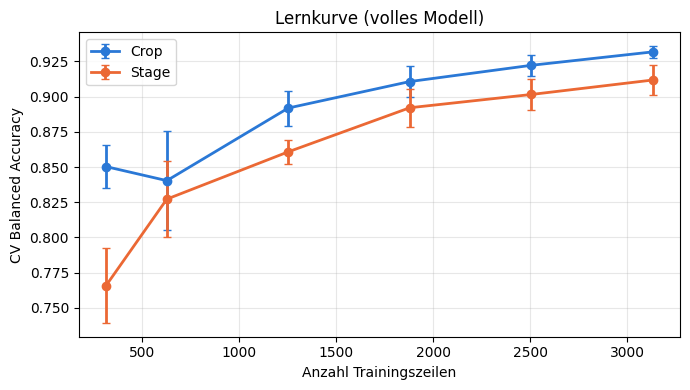

,Crop,Crop std,Stage,Stage std
Trainingszeilen,,,,
313,0.850,0.015,0.766,0.027
626,0.840,0.035,0.827,0.027
1252,0.892,0.012,0.861,0.008
1878,0.911,0.011,0.892,0.014
2504,0.922,0.007,0.902,0.011
3130,0.932,0.004,0.912,0.011


In [8]:
TRAIN_SIZES = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
lc = {}
for target, (y, scoring) in FIT_TARGETS.items():
    n_train, _, val = learning_curve(make_pipe(target, N_FULL), X_fe_train, y, cv=cv_folds, train_sizes=TRAIN_SIZES,
                                     scoring=scoring, shuffle=True, random_state=RANDOM_STATE, n_jobs=-1)
    lc[target] = val.mean(axis=1)
    lc[target + ' std'] = val.std(axis=1)
lc = pd.DataFrame(lc, index=pd.Index(n_train, name='Trainingszeilen'))

fig, ax = plt.subplots(figsize=(7, 4))
for target in FIT_TARGETS:
    ax.errorbar(lc.index, lc[target], yerr=lc[target + ' std'], marker='o', lw=2, capsize=3, label=target)
ax.set(xlabel='Anzahl Trainingszeilen', ylabel='CV Balanced Accuracy', title='Lernkurve (volles Modell)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
lc.round(3)

## Trade-off „Qualität vs. Input"

Alle Konfigurationen im Überblick, dazu die Kurve CV Balanced Accuracy gegen die Anzahl spektraler Eingaben. Das graue Band markiert eine Toleranz von **0.01** unter dem vollen Modell, das ist etwa die Fold-Streuung aus M2 (Std 0.003–0.009).

,studie,konfiguration,n_baender,n_features,Crop,Stage
7,Feature-Gruppen,nur Month/AEZ,0,8,0.699,0.642
10,Gleichmäßig,3 Bänder gleichmäßig verteilt,3,11,0.832,0.844
11,SelectKBest,3 Bänder SelectKBest (F-Test),3,11,0.768,0.786
13,Gleichmäßig,5 Bänder gleichmäßig verteilt,5,13,0.859,0.882
14,SelectKBest,5 Bänder SelectKBest (F-Test),5,13,0.770,0.795
16,Gleichmäßig,10 Bänder gleichmäßig verteilt,10,18,0.891,0.900
17,SelectKBest,10 Bänder SelectKBest (F-Test),10,18,0.815,0.831
28,Sentinel-2,Sentinel-2: 11 Bänder + Month/AEZ,11,19,0.903,0.898
29,Sentinel-2,Sentinel-2: 11 Bänder + Indizes + Month/AEZ,11,41,0.901,0.886
9,Indizes,12 Indizes + ihre 20 Bänder + Month/AEZ,20,40,0.908,0.913


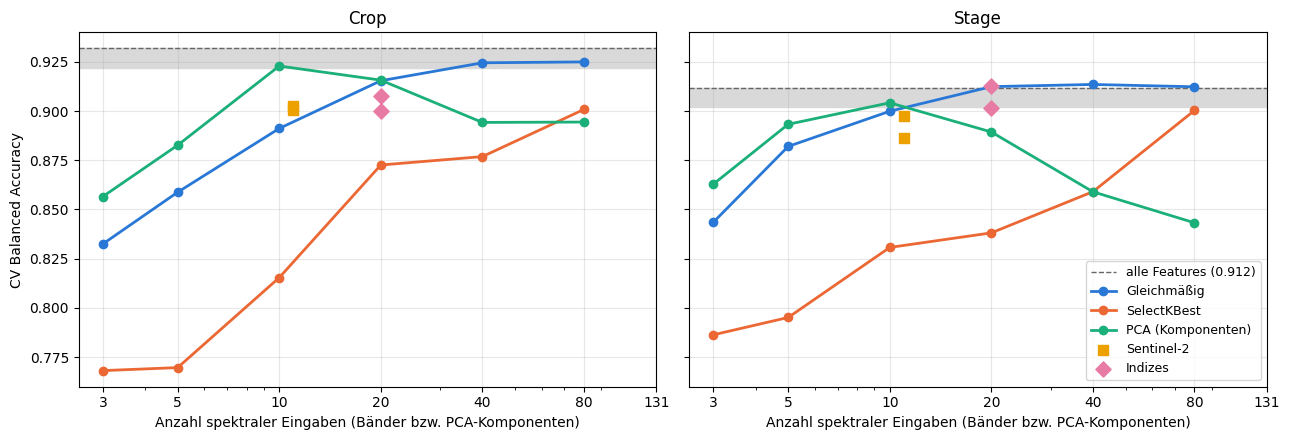

In [9]:
res = pd.DataFrame(results)
full = res.iloc[0]
TOL = 0.01
display(res.drop(columns='k').sort_values(['n_baender', 'Stage'], ascending=[True, False]).round(3))

method_style = {'Gleichmäßig': 'C0', 'SelectKBest': 'C1', 'PCA': 'C2'}
point_style = {'Sentinel-2': ('C3', 's'), 'Indizes': ('C4', 'D')}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, target in zip(axes, ['Crop', 'Stage']):
    ax.axhspan(full[target] - TOL, full[target], color='0.85', zorder=0)
    ax.axhline(full[target], color='0.4', lw=1, ls='--', label=f'alle Features ({full[target]:.3f})')
    for study, color in method_style.items():
        s = res[res.studie == study]
        ax.plot(s.k, s[target], marker='o', lw=2, color=color, label=study + (' (Komponenten)' if study == 'PCA' else ''))
    for study, (color, marker) in point_style.items():
        s = res[res.studie == study]
        ax.scatter(s.n_baender, s[target], color=color, marker=marker, s=60, zorder=3, label=study)
    ax.set_xscale('log')
    ax.set_xticks([3, 5, 10, 20, 40, 80, 131], labels=[3, 5, 10, 20, 40, 80, 131])
    ax.set(title=target, xlabel='Anzahl spektraler Eingaben (Bänder bzw. PCA-Komponenten)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('CV Balanced Accuracy')
axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

### Auswahl eines reduzierten Modells

Regel: die Konfiguration mit den **wenigsten zu messenden Bändern**, die bei Crop **und** Stage höchstens 0.01 unter dem vollen Modell liegt. PCA scheidet aus, weil sie alle Bänder braucht. Die Auswahl erfolgt nur per CV. Danach wird das reduzierte Set mit dem gleichen Budget wie in M2 neu getunt (20 Kandidaten × 5 Folds) und einmalig auf dem Testsplit gegen das volle M2-Modell verglichen.

In [10]:
reduced = res[(res.studie != 'PCA') & res.n_baender.between(1, len(bands) - 1)]
within = reduced[(reduced.Crop >= full.Crop - TOL) & (reduced.Stage >= full.Stage - TOL)]
if within.empty:  # nichts innerhalb der Toleranz -> bestes reduziertes Set
    chosen = reduced.loc[(reduced.Crop + reduced.Stage).idxmax()]
else:
    chosen = within.sort_values(['n_baender', 'Stage'], ascending=[True, False]).iloc[0]
cfg = configs[chosen.konfiguration]
print(f"Ausgewählt: {chosen.konfiguration} — {chosen.n_baender} Bänder, {cfg['n_features']} Features, "
      f"CV Crop {chosen.Crop:.3f} / Stage {chosen.Stage:.3f}")

n = cfg['n_features']
grid = {'clf__C': loguniform(1e-1, 1e3), 'clf__gamma': loguniform(1e-4 * N_FULL / n, 1e-1 * N_FULL / n),
        'clf__class_weight': [None, 'balanced']}
tuned_reduced = {}
for target, (y, scoring) in FIT_TARGETS.items():
    search = RandomizedSearchCV(make_pipe(target, n, cfg['pre']), grid, n_iter=20, cv=cv_folds, scoring=scoring,
                                random_state=RANDOM_STATE, n_jobs=-1).fit(df.loc[train_idx, cfg['cols']], y)
    tuned_reduced[target] = search.best_estimator_
    print(f'{target} getunt: CV {search.best_score_:.3f}',
          {k: (round(v, 5) if isinstance(v, float) else v) for k, v in search.best_params_.items()})

Ausgewählt: 40 Bänder gleichmäßig verteilt — 40 Bänder, 48 Features, CV Crop 0.925 / Stage 0.914
Crop getunt: CV 0.925 {'clf__C': np.float64(138.26232), 'clf__class_weight': None, 'clf__gamma': np.float64(0.0048)}
Stage getunt: CV 0.914 {'clf__C': np.float64(785.27555), 'clf__class_weight': None, 'clf__gamma': np.float64(0.00798)}


,Crop BAcc,Crop Macro F1,Stage BAcc,Stage Macro F1
Modell,,,,
"Voll (M2): 131 Bänder, 164 Features",0.922,0.923,0.908,0.909
"Reduziert, M2-Parameter: 40 Bänder gleichmäßig verteilt",0.906,0.910,0.916,0.915
"Reduziert, neu getunt: 40 Bänder gleichmäßig verteilt",0.906,0.910,0.916,0.915


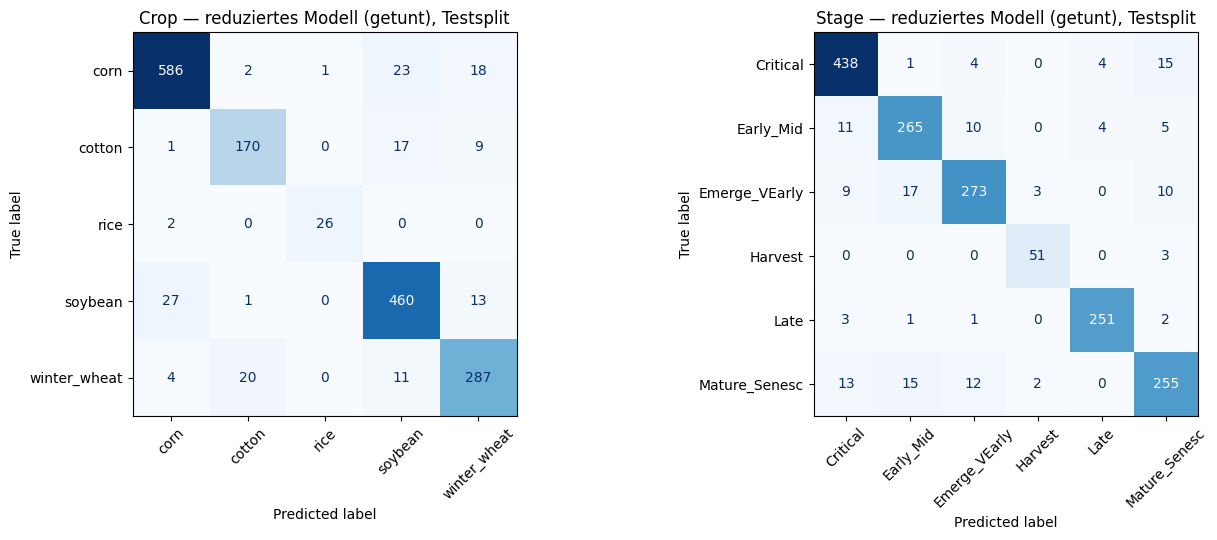

In [11]:
def fit_models(cols, n_features, pre=None):
    return {t: make_pipe(t, n_features, pre).fit(df.loc[train_idx, cols], y) for t, (y, _) in FIT_TARGETS.items()}


def predict(models, target, X):
    pred = models[target].predict(X)
    return split_joint(pred)[1] if target == 'Stage' else pred


final_full = fit_models(feature_cols_fe, N_FULL)
candidates = {
    f'Voll (M2): {len(bands)} Bänder, {N_FULL} Features': (final_full, feature_cols_fe),
    f"Reduziert, M2-Parameter: {chosen.konfiguration}": (fit_models(cfg['cols'], n, cfg['pre']), cfg['cols']),
    f"Reduziert, neu getunt: {chosen.konfiguration}": (tuned_reduced, cfg['cols']),
}
test_rows, test_preds = [], {}
for name, (models, cols) in candidates.items():
    row = {'Modell': name}
    for target, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        pred = test_preds[name, target] = predict(models, target, df.loc[test_idx, cols])
        row[f'{target} BAcc'] = balanced_accuracy_score(y_true, pred)
        row[f'{target} Macro F1'] = f1_score(y_true, pred, average='macro')
    test_rows.append(row)
test_results = pd.DataFrame(test_rows).set_index('Modell')
display(test_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (target, y_true) in zip(axes, [('Crop', y_crop_test), ('Stage', y_stage_test)]):
    ConfusionMatrixDisplay.from_predictions(y_true, test_preds[list(candidates)[2], target], ax=ax,
                                            xticks_rotation=45, colorbar=False, cmap='Blues')
    ax.set_title(f'{target} — reduziertes Modell (getunt), Testsplit')
plt.tight_layout()
plt.show()

## Bonus 1: Gruppierte Permutation Importance (SVM, Testsplit)

Wie stark fällt die Test-Balanced-Accuracy des vollen M2-Modells, wenn eine Feature-Gruppe zufällig permutiert wird (5 Wiederholungen)? Wir permutieren **Gruppen** (Spektralregionen, Indizes, Metadaten) statt einzelner Bänder: Benachbarte Bänder sind stark korreliert (vgl. EDA), und bei einem permutierten Einzelband springen die Nachbarbänder ein — die Einzelband-Wichtigkeit wäre fast überall ≈ 0. Auch zwischen den Gruppen gibt es Redundanz (z. B. stecken Red-Edge-Informationen auch in NDRE/REP). Ein kleiner Abfall heißt deshalb „ersetzbar", nicht „irrelevant".

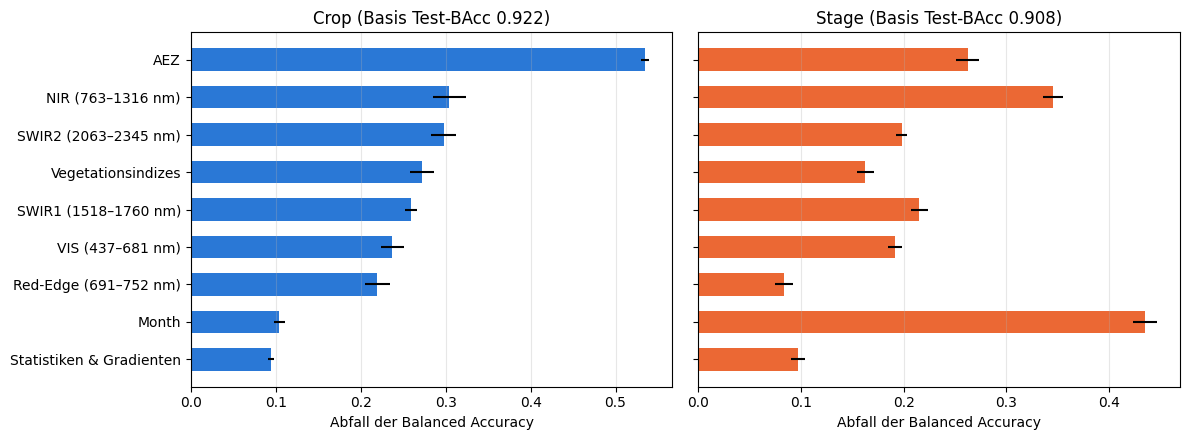

,target,Crop,Stage
Gruppe,n,,
AEZ,7,0.535,0.262
NIR (763–1316 nm),45,0.304,0.346
SWIR2 (2063–2345 nm),29,0.298,0.198
Vegetationsindizes,12,0.272,0.163
SWIR1 (1518–1760 nm),25,0.260,0.215
VIS (437–681 nm),25,0.237,0.192
Red-Edge (691–752 nm),7,0.220,0.083
Month,3,0.104,0.435
Statistiken & Gradienten,11,0.095,0.097


In [12]:
def region(lo, hi):
    return [b for b, w in zip(bands, wl) if lo <= w < hi]


GROUPS = {
    'VIS (437–681 nm)': region(0, 690),
    'Red-Edge (691–752 nm)': region(690, 760),
    'NIR (763–1316 nm)': region(760, 1400),
    'SWIR1 (1518–1760 nm)': region(1400, 1900),
    'SWIR2 (2063–2345 nm)': region(1900, 3000),
    'Vegetationsindizes': INDICES,
    'Statistiken & Gradienten': [c for c in eng_cols if c not in INDICES and not c.startswith(('AEZ_', 'Month'))],
    'Month': [c for c in feature_cols_fe if c.startswith('Month')],
    'AEZ': [c for c in META if c.startswith('AEZ_')],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(feature_cols_fe), 'Gruppen müssen alle Features genau einmal abdecken'

N_REPEATS = 5
rng = np.random.default_rng(RANDOM_STATE)
y_test = {'Crop': y_crop_test, 'Stage': y_stage_test}
base = {t: balanced_accuracy_score(y_test[t], predict(final_full, t, X_fe_test)) for t in y_test}
perm_rows = []
for group, cols in GROUPS.items():
    for target in y_test:
        drops = []
        for _ in range(N_REPEATS):
            X_perm = X_fe_test.copy()
            X_perm[cols] = X_perm[cols].to_numpy()[rng.permutation(len(X_perm))]  # ganze Gruppe zeilenweise gemeinsam
            drops.append(base[target] - balanced_accuracy_score(y_test[target], predict(final_full, target, X_perm)))
        perm_rows.append({'Gruppe': group, 'n': len(cols), 'target': target, 'drop': np.mean(drops), 'std': np.std(drops)})
perm = pd.DataFrame(perm_rows).pivot(index=['Gruppe', 'n'], columns='target', values=['drop', 'std'])
perm = perm.sort_values(('drop', 'Crop'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, target, color in zip(axes, ['Crop', 'Stage'], ['C0', 'C1']):
    ax.barh([g for g, _ in perm.index], perm[('drop', target)], xerr=perm[('std', target)], color=color, height=0.6)
    ax.set(title=f'{target} (Basis Test-BAcc {base[target]:.3f})', xlabel='Abfall der Balanced Accuracy')
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
perm['drop'].sort_values('Crop', ascending=False).round(3)

## Bonus 2: SHAP — welche Wellenlängen unterscheiden welche Klasse?

Für die Frage, *welche Wellenlängen* für *welche Klasse* wichtig sind, eignet sich SHAP auf einem Baum-Modell: `TreeExplainer` rechnet exakt und schnell, während ein `KernelExplainer` auf der SVM bei 164 Features nur grob approximieren könnte. Wir trainieren dazu je ein HistGradientBoosting (Default-Parameter) auf den **131 Rohbändern + Month/AEZ** — ohne abgeleitete Indizes, damit sich die Wichtigkeit direkt den Wellenlängen zuordnen lässt — und erklären 500 Testzeilen. Pro Klasse wird das mittlere |SHAP| (one-vs-rest-Beitrag zum Logit) berechnet und
1. als **Heatmap** pro Spektralregion zusammengefasst: Anteil der Region am gesamten |SHAP| der Klasse in %. In Klammern steht die Anzahl Bänder, denn größere Regionen sammeln mehr Anteil.
2. als **Kurve je Band** gezeigt, summiert über die Klassen und normiert auf 100 % je Zielgröße. Darüber steht das mittlere Spektrum je Crop, die Lücken sind die entfernten Wasserdampf-Bänder.

Einschränkungen: Das HGB ist nicht das finale Modell und etwas schwächer (Test-BAcc siehe Ausgabe). Bei korrelierten Nachbarbändern verteilt ein Baum-Modell die Wichtigkeit eher zufällig auf eines davon. Daher ist auf **Regionen** zu achten, nicht auf Einzelbänder.

Crop: HGB auf Rohbändern + Month/AEZ, Test-BAcc 0.867
Stage: HGB auf Rohbändern + Month/AEZ, Test-BAcc 0.875


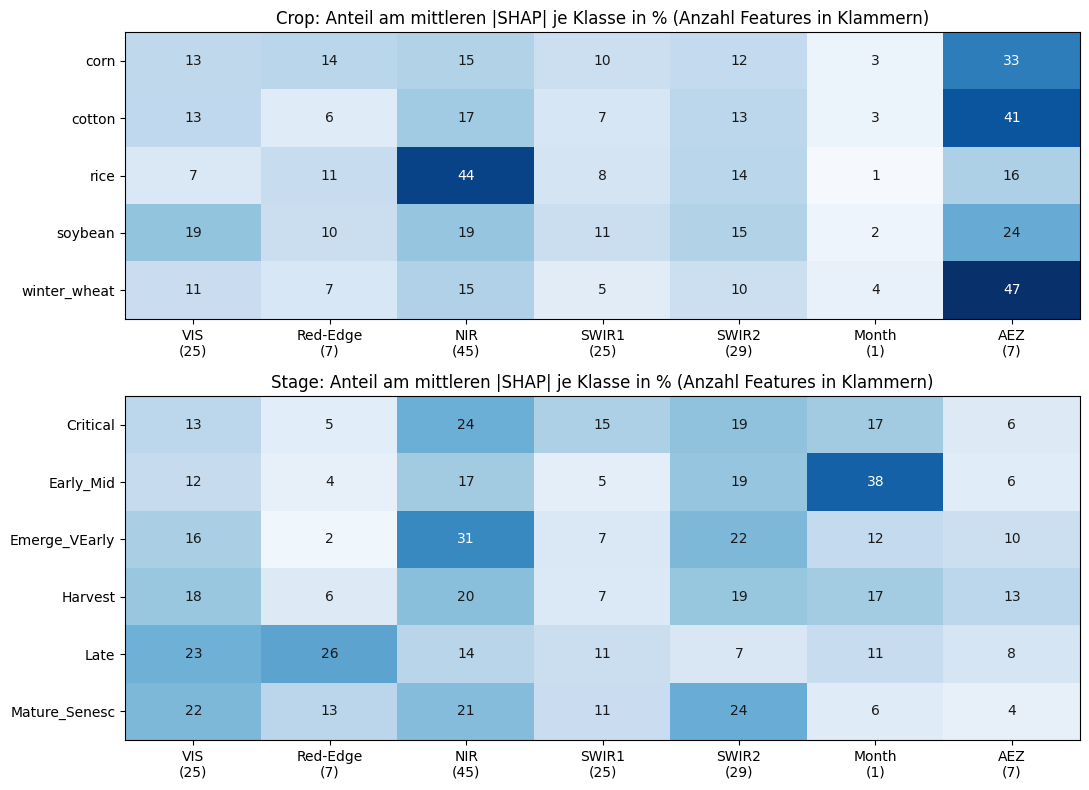

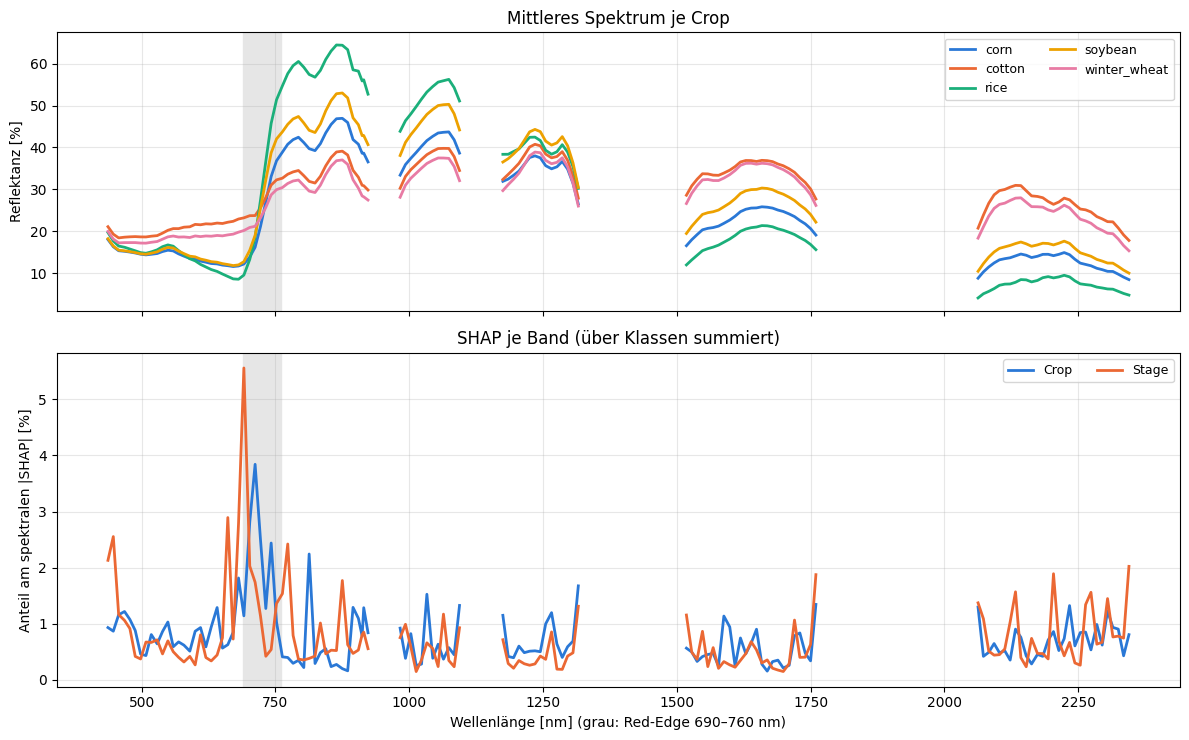

,Top-5 Wellenlängen [nm] nach mittlerem |SHAP|
Crop: corn,"[712, 722, 1588, 702, 1599]"
Crop: cotton,"[1760, 457, 468, 702, 1094]"
Crop: rice,"[813, 1033, 742, 895, 681]"
Crop: soybean,"[641, 712, 742, 702, 2234]"
Crop: winter_wheat,"[702, 712, 1094, 1316, 722]"
Stage: Critical,"[2133, 447, 2204, 1760, 1548]"
Stage: Early_Mid,"[1064, 2305, 763, 2063, 2345]"
Stage: Emerge_VEarly,"[773, 2274, 681, 875, 2264]"
Stage: Harvest,"[2345, 763, 752, 447, 681]"
Stage: Late,"[691, 661, 702, 712, 681]"


In [13]:
gap_pos = np.where(np.diff(wl) > 30)[0] + 1


def gapped(y):
    # NaN in die Wasserdampf-Lücken einfügen, damit die Linien dort unterbrochen werden
    return np.insert(wl.astype(float), gap_pos, np.nan), np.insert(np.asarray(y, dtype=float), gap_pos, np.nan)


shap_cols = bands + META
SHAP_GROUPS = {g: GROUPS[g] for g in list(GROUPS)[:5]} | {'Month': ['Month'], 'AEZ': GROUPS['AEZ']}
X_shap = df.loc[test_idx, shap_cols].sample(500, random_state=RANDOM_STATE)

shap_imp, shap_share = {}, {}
for target in ['Crop', 'Stage']:
    hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(df.loc[train_idx, shap_cols], df.loc[train_idx, target])
    bacc = balanced_accuracy_score(df.loc[test_idx, target], hgb.predict(df.loc[test_idx, shap_cols]))
    print(f'{target}: HGB auf Rohbändern + Month/AEZ, Test-BAcc {bacc:.3f}')
    sv = shap.TreeExplainer(hgb).shap_values(X_shap)  # (Zeilen, Features, Klassen)
    imp = shap_imp[target] = pd.DataFrame(np.abs(sv).mean(axis=0), index=shap_cols, columns=hgb.classes_)
    share = pd.DataFrame({g: imp.loc[cols].sum() for g, cols in SHAP_GROUPS.items()})  # Klassen x Gruppen
    shap_share[target] = 100 * share.div(share.sum(axis=1), axis=0)

# 1. Heatmap: Anteil jeder Region am |SHAP| einer Klasse
vmax = max(s.to_numpy().max() for s in shap_share.values())
fig, axes = plt.subplots(2, 1, figsize=(11, 8), height_ratios=[5, 6])
for ax, (target, s) in zip(axes, shap_share.items()):
    ax.imshow(s, cmap='Blues', vmin=0, vmax=vmax, aspect='auto')
    ax.set_xticks(range(s.shape[1]), [f"{g.split(' (')[0]}\n({len(SHAP_GROUPS[g])})" for g in s.columns])
    ax.set_yticks(range(s.shape[0]), s.index)
    for (i, j), v in np.ndenumerate(s.to_numpy()):
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', color='white' if v > vmax * 0.6 else '0.1')
    ax.set_title(f'{target}: Anteil am mittleren |SHAP| je Klasse in % (Anzahl Features in Klammern)')
plt.tight_layout()
plt.show()

# 2. Kurve je Band, über Klassen summiert und auf 100 % normiert
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, height_ratios=[1, 1.2])
for crop, spec in df.groupby('Crop')[bands].mean().iterrows():
    axes[0].plot(*gapped(spec), lw=2, label=crop)
axes[0].set(ylabel='Reflektanz [%]', title='Mittleres Spektrum je Crop')
for target, color in zip(shap_imp, ['C0', 'C1']):
    per_band = shap_imp[target].loc[bands].sum(axis=1)
    axes[1].plot(*gapped(100 * per_band / per_band.sum()), lw=2, color=color, label=target)
axes[1].set(ylabel='Anteil am spektralen |SHAP| [%]', title='SHAP je Band (über Klassen summiert)')
for ax in axes:
    ax.axvspan(690, 760, color='0.9', zorder=0)  # Red-Edge
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9, ncol=2, loc='upper right')
axes[-1].set_xlabel('Wellenlänge [nm] (grau: Red-Edge 690–760 nm)')
plt.tight_layout()
plt.show()

pd.Series({f'{t}: {c}': imp.loc[bands, c].nlargest(5).index.map(lambda b: int(b[1:])).tolist()
           for t, imp in shap_imp.items() for c in imp},
          name='Top-5 Wellenlängen [nm] nach mittlerem |SHAP|').to_frame()

## Zusammenfassung

Laufzeit des Notebooks: ca. 15 Min. auf 8 Kernen. **Plausibilität:** Mit allen Features reproduziert das feste Modell die M2-CV exakt (Crop 0.932, Stage 0.912), auf dem Testsplit ebenso (0.922 / 0.908).

**Trade-off „Qualität vs. Input" (CV Balanced Accuracy, jeweils + Month/AEZ):**

| Input | gemessene Bänder | Crop | Stage |
|---|---|---|---|
| Alle Features (M2) | 131 | 0.932 | 0.912 |
| 40 Bänder gleichmäßig (**ausgewählt**) | 40 | 0.925 | 0.914 |
| 20 Bänder gleichmäßig | 20 | 0.915 | 0.912 |
| 12 Indizes + ihre 20 Bänder | 20 | 0.908 | 0.913 |
| Sentinel-2 simuliert | 11 | 0.903 | 0.898 |
| 10 Bänder gleichmäßig | 10 | 0.891 | 0.900 |
| 3 Bänder gleichmäßig | 3 | 0.832 | 0.844 |
| nur Month/AEZ | 0 | 0.699 | 0.642 |

**Beobachtungen**
- **Die Kurve bleibt bis ~20 Bänder flach:** Mit 15 % der Bänder (20 gleichmäßig verteilt) verliert Crop 0.017, Stage nichts. Darunter fällt die Leistung deutlich (10 Bänder: −0.04 / −0.01, 3 Bänder: −0.10 / −0.07). Stage verkraftet die Bandreduktion besser als Crop.
- **Ausgewähltes Modell (Toleranz 0.01): 40 gleichmäßig verteilte Bänder** (−70 % Bänder, 48 statt 164 Features). Testsplit: Crop 0.906 (voll 0.922, −0.016), Stage 0.916 (voll 0.908, +0.008). Im Mittel gleichauf. Der Crop-Verlust ist auf dem Test größer als in der CV (−0.007) — im Rahmen eines einzelnen Splits, aber ein Hinweis, dass Crop von der vollen Auflösung leicht profitiert. Das Neu-Tuning wählt denselben Kandidaten wie M2 (gleicher Seed, mitskalierter gamma-Bereich) und bestätigt damit die gamma-Skalierung.
- **Abdeckung schlägt Trennschärfe:** `SelectKBest` liegt bei jedem k klar unter der gleichmäßigen Auswahl, weil der F-Test Cluster redundanter Nachbarbänder wählt (Crop, k=10: nur 600–691 nm; Stage: 773/783 nm + SWIR2). Wichtiger als das einzelne trennscharfe Band ist, dass VIS, Red-Edge, NIR und beide SWIR-Bereiche vertreten sind.
- **PCA** erreicht mit 10 Komponenten fast die volle Crop-Leistung (0.923), braucht aber alle 131 Bänder als Messung, ist also keine Datenreduktion. Der Abfall ab 20 Komponenten ist ein Artefakt: Der `StandardScaler` hinter der PCA bringt auch die varianzarmen Rauschkomponenten auf Varianz 1 (Whitening), und diese dominieren dann den RBF-Abstand.
- **Feature Engineering:** Rohbänder + Month/AEZ ohne FE erreichen 0.922 / 0.916. FE hilft der SVM nur bei Crop (+0.010). Die 12 Vegetationsindizes allein (aus 20 Bändern) erreichen 0.900 / 0.901 — kompakt und physikalisch interpretierbar.
- **Sentinel-2** (11 simulierte Bänder): 0.903 / 0.898, also −0.03 / −0.014 ggü. Hyperion. Neu berechnete Indizes bringen dort nichts. Ein frei verfügbarer Multispektralsensor erreicht damit ~97–98 % der Leistung. Das ist eine Obergrenze, weil die Simulation idealisiert ist.
- **Metadaten:** Month + AEZ allein erreichen 0.70 / 0.64 (Zufall 0.20 / 0.17). Ohne AEZ verliert Crop 0.049, ohne Month verliert Stage 0.031, ohne beides −0.066 / −0.055. Sie kosten nichts, binden das Modell aber an die Regionen und Saisonverteilung des Datensatzes. Der Validierungsdatensatz (`test.csv`) hat fast identische AEZ- und Monatsanteile (Abweichung ≤ 1,5 Prozentpunkte), für die Abgabe ist das also unkritisch. Für eine Übertragung auf neue Regionen ist es ein Risiko.
- **Aufnahmezeitpunkt:** Juli und August sind am zuverlässigsten (Crop 0.953 / 0.976, Stage 0.952 / 0.969), Mai und Oktober am schwächsten (Crop 0.791 / 0.855). Beim Auflaufen und nach der Ernte dominiert das Bodensignal. Im Sommerfenster Juni–August erreicht Crop 0.953. Für Stage ist Juli–September (0.929) das bessere Fenster, weil dort alle Stadien vorkommen. Die Monate haben aber unterschiedliche Klassenmengen (`rice` nur im August), die Werte sind also nur eingeschränkt vergleichbar.
- **Trainingsdaten:** Die Lernkurve steigt noch, um ca. +0.01 pro +20 % Daten (80 % → 0.922 / 0.902, 100 % → 0.932 / 0.912). Weniger Trainingsdaten kosten also direkt Leistung, mehr gelabelte Daten wären der wirksamste Hebel.

**Bonus — Erklärbarkeit**
- **Permutation Importance (SVM, Test):** Für Crop ist AEZ die wichtigste Gruppe (Abfall 0.54), dann NIR (0.30), SWIR2 (0.30) und die Indizes (0.27). Für Stage führt Month (0.44) vor NIR (0.35) und AEZ (0.26). Red-Edge wirkt hier klein (0.22 / 0.08), weil dieselbe Information auch in den Indizes (NDRE, REP, CI) und den Nachbarregionen steckt.
- **SHAP (HGB, Rohbänder + Month/AEZ):** **Pro Band ist der Red-Edge am informativsten.** 7 Bänder tragen 2–26 % des |SHAP| einer Klasse, und die Kurve hat ihren Peak bei ~700 nm (Stage) bzw. ~712 nm (Crop). Fachlich passt das: Die Red-Edge-Position verschiebt sich mit dem Chlorophyllgehalt.
  - `Late` und `Mature_Senesc` stützen sich auf Red-Edge und VIS (Chlorophyllabbau, Seneszenz) sowie SWIR2 (Trockensubstanz, Lignin/Zellulose um 2100–2300 nm).
  - `rice` wird über NIR erkannt (44 %): höchste NIR-Reflektanz, dichter Bestand im August.
  - `winter_wheat` und `cotton` über AEZ (47 / 41 %): Sie werden regional angebaut.
  - `Early_Mid` über den Monat (38 %).

**Fazit:** Für die Abgabe bleibt das volle M2-Modell die erste Wahl (beste Crop-Leistung, die Validierungsdaten enthalten alle Bänder). Auf die Datenreduktions-Frage lautet die Antwort: **20–40 gleichmäßig über das Spektrum verteilte Bänder + Month/AEZ erreichen ≥ 98 % der Leistung, 11 Sentinel-2-Bänder ~97 %.** Unter ~10 Bändern bricht die Leistung ein.

**Einschränkungen:** ein Split und ein Seed. Statt eines Tunings pro Konfiguration wird gamma skaliert (Ausnahme: das ausgewählte Set). Die Sentinel-2-Simulation ist idealisiert (Rechteckfilter, gleiche Auflösung und Atmosphäre). SHAP läuft auf einem HGB statt auf der SVM. Die Monatswerte beruhen auf unterschiedlichen Klassenmengen.